In [ ]:
# 1. Force static inline rendering for Matplotlib & Seaborn
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# Increase dots per inch (DPI) for crisp, clear printed plots
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150

# 2. Force Plotly to render as static PNG images instead of interactive JavaScript
import plotly.io as pio
pio.renderers.default = "png"

print("Setup complete! All plots are now optimized for printing.")

Setup complete! All plots are now optimized for printing.


In [ ]:
# ============================================================
# CELL 1 — INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install -U \
    kagglehub \
    pandas numpy \
    pillow \
    opencv-python-headless \
    pydicom \
    openpyxl \
    tqdm

print("✅ Libraries installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 95.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 94.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 9.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.3 which is incompatible.


In [ ]:
# ============================================================
# CELL 2 — IMPORTS + PROJECT SETUP
# ============================================================

import os
import re
import json
import shutil
import random
import warnings
from pathlib import Path
from collections import defaultdict

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from PIL import Image

import cv2
import pydicom

from tqdm.auto import tqdm

import torch

print("✅ Imports successful.")
print("PyTorch:", torch.__version__)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

✅ Imports successful.
PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# CELL 3 — CREATE PROJECT DIRECTORIES
# ============================================================

PROJECT_ROOT = Path(
    "/content/TB_Multimodal_Project"
)

if PROJECT_ROOT.exists():
    shutil.rmtree(
        PROJECT_ROOT
    )

folders = [
    "data",
    "data/kaggle",
    "data/images",
    "data/metadata",
    "models",
    "outputs",
    "app"
]

for folder in folders:
    (
        PROJECT_ROOT / folder
    ).mkdir(
        parents=True,
        exist_ok=True
    )

print(
    "✅ Project directory created:"
)

print(
    PROJECT_ROOT
)

✅ Project directory created:
/content/TB_Multimodal_Project


In [ ]:
# ============================================================
# CELL 4 — KAGGLE DATASET CONFIGURATION
# ============================================================

KAGGLE_DATASET = (
    "raddar/drug-resistant-tuberculosis-xrays"
)

print(
    "Kaggle dataset:"
)

print(
    KAGGLE_DATASET
)

print(
    "\n✅ No Excel upload required."
)

print(
    "✅ No image ZIP upload required."
)

print(
    "The notebook will attempt to download the dataset directly."
)

Kaggle dataset:
raddar/drug-resistant-tuberculosis-xrays

✅ No Excel upload required.
✅ No image ZIP upload required.
The notebook will attempt to download the dataset directly.


In [ ]:
# ============================================================
# CELL 5 — DOWNLOAD DATASET DIRECTLY FROM KAGGLE
# ============================================================

import kagglehub

KAGGLE_DIR = (
    PROJECT_ROOT /
    "data" /
    "kaggle"
)

print(
    "Downloading Kaggle dataset..."
)

try:

    downloaded_path = kagglehub.dataset_download(
        KAGGLE_DATASET,
        output_dir=str(KAGGLE_DIR)
    )

    downloaded_path = Path(
        downloaded_path
    )

    print(
        "\n✅ DOWNLOAD COMPLETED"
    )

    print(
        "Dataset path:"
    )

    print(
        downloaded_path
    )

except Exception as e:

    print(
        "\n❌ DOWNLOAD FAILED"
    )

    print(
        type(e).__name__
    )

    print(
        str(e)
    )

    raise

Using Colab cache for faster access to the 'drug-resistant-tuberculosis-xrays' dataset.

✅ DOWNLOAD COMPLETED
Dataset path:
/kaggle/input/drug-resistant-tuberculosis-xrays


In [ ]:
# ============================================================
# CELL 6 — INSPECT DOWNLOADED DATASET
# ============================================================

DATA_ROOT = Path(
    downloaded_path
)

all_files = [
    p
    for p in DATA_ROOT.rglob("*")
    if p.is_file()
]

print(
    "Dataset root:"
)

print(
    DATA_ROOT
)

print(
    "\nTotal files:",
    len(all_files)
)

print(
    "\nFirst 100 files:"
)

for p in all_files[:100]:

    relative = p.relative_to(
        DATA_ROOT
    )

    size_mb = (
        p.stat().st_size
        /
        (1024 ** 2)
    )

    print(
        f"{relative} "
        f"-> {size_mb:.2f} MB"
    )

Dataset root:
/kaggle/input/drug-resistant-tuberculosis-xrays

Total files: 1049

First 100 files:
tbportals_metadata.csv -> 0.20 MB
images/images/1.2.840.114062.2.192.168.196.13.2015.2.6.13.10.6.15062015.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.207732457674374.27968.20150929060043.36.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807024729.15.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807025109.17.dcm -> 9.64 MB
images/images/1.3.6.1.4.1.25403.158515237678667.2100.20150226021657.3.dcm -> 9.64 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807022744.12.dcm -> 9.64 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807021719.3.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807023316.17.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807022805.7.dcm -> 11.68 MB
images/images/1.3.6.1.4.1.25403.158515237678667.5060.20130807024729.18.dcm -> 11.68 MB
i

In [ ]:
# ============================================================
# CELL 7 — FIND IMAGE + METADATA FILES
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
    ".dcm",
    ".dicom"
}

TABULAR_EXTENSIONS = {
    ".csv",
    ".xlsx",
    ".xls",
    ".json"
}

IMAGE_FILES = [
    p
    for p in all_files
    if p.suffix.lower()
    in IMAGE_EXTENSIONS
]

TABULAR_FILES = [
    p
    for p in all_files
    if p.suffix.lower()
    in TABULAR_EXTENSIONS
]

print(
    "✅ Image / DICOM files:",
    len(IMAGE_FILES)
)

print(
    "\n✅ Metadata / tabular files:",
    len(TABULAR_FILES)
)

print(
    "\nMetadata files:"
)

for p in TABULAR_FILES:

    print(
        " -",
        p.relative_to(
            DATA_ROOT
        )
    )

✅ Image / DICOM files: 1047

✅ Metadata / tabular files: 1

Metadata files:
 - tbportals_metadata.csv


In [ ]:
# ============================================================
# CELL 8 — LOAD ALL METADATA TABLES
# ============================================================

TABLES = {}

for path in TABULAR_FILES:

    print(
        "\n" + "=" * 80
    )

    print(
        "FILE:",
        path.name
    )

    try:

        suffix = path.suffix.lower()

        if suffix == ".csv":

            df_tmp = pd.read_csv(
                path,
                low_memory=False
            )

        elif suffix in {
            ".xlsx",
            ".xls"
        }:

            df_tmp = pd.read_excel(
                path
            )

        elif suffix == ".json":

            try:

                df_tmp = pd.read_json(
                    path
                )

            except:

                with open(
                    path,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:

                    data = json.load(f)

                df_tmp = pd.DataFrame(
                    data
                )

        else:

            continue

        df_tmp.columns = [
            str(c).strip()
            for c in df_tmp.columns
        ]

        TABLES[
            str(path)
        ] = df_tmp

        print(
            "Shape:",
            df_tmp.shape
        )

        print(
            "\nColumns:"
        )

        for c in df_tmp.columns:
            print(
                " -",
                c
            )

        print(
            "\nPreview:"
        )

        display(
            df_tmp.head(5)
        )

    except Exception as e:

        print(
            "Could not read file:",
            type(e).__name__
        )

        print(
            str(e)
        )

print(
    "\n✅ Successfully loaded tables:",
    len(TABLES)
)


FILE: tbportals_metadata.csv
Shape: (1050, 6)

Columns:
 - filename
 - study_id
 - patient_identifier
 - patient_id
 - gender
 - tb_localization

Preview:


,filename,study_id,patient_identifier,patient_id,gender,tb_localization
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,72,6c624eed-fc47-4a7e-8876-af8787f55737,male,Pulmonary tuberculosis and extrapulmonary tube...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis



✅ Successfully loaded tables: 1


In [ ]:
# ============================================================
# CELL 9 — SEARCH FOR MDR / PRE-XDR / XDR LABELS
# ============================================================

CLASS_NAMES = [
    "MDR",
    "PRE-XDR",
    "XDR"
]


def normalize_resistance_label(
    value
):

    if pd.isna(value):

        return None

    s = str(
        value
    ).strip().upper()

    s = (
        s.replace("_", "")
         .replace("-", "")
         .replace(" ", "")
         .replace("/", "")
    )

    # IMPORTANT:
    # Check PRE-XDR before generic XDR
    if "PREXDR" in s:

        return "PRE-XDR"

    if s == "MDR":

        return "MDR"

    if "MDRTB" in s:

        return "MDR"

    if s == "XDR":

        return "XDR"

    if "XDRTB" in s:

        return "XDR"

    if "MULTIDRUGRESIST" in s:

        return "MDR"

    if "EXTENSIVELYDRUGRESIST" in s:

        return "XDR"

    return None


LABEL_CANDIDATES = []

for table_path, df_tmp in TABLES.items():

    for col in df_tmp.columns:

        normalized = (
            df_tmp[col]
            .map(
                normalize_resistance_label
            )
        )

        valid_count = (
            normalized.notna().sum()
        )

        found_classes = set(
            normalized.dropna().unique()
        )

        class_overlap = (
            found_classes
            &
            set(CLASS_NAMES)
        )

        if (
            valid_count >= 10
            and len(class_overlap) >= 2
        ):

            LABEL_CANDIDATES.append({

                "file":
                    table_path,

                "column":
                    col,

                "valid_rows":
                    int(valid_count),

                "classes":
                    sorted(
                        class_overlap
                    )
            })


print(
    "Possible resistance-label columns:"
)

if LABEL_CANDIDATES:

    display(
        pd.DataFrame(
            LABEL_CANDIDATES
        )
    )

else:

    print(
        "❌ No obvious MDR/PRE-XDR/XDR "
        "label column detected."
    )

Possible resistance-label columns:
❌ No obvious MDR/PRE-XDR/XDR label column detected.


In [ ]:
# ============================================================
# CELL 10B — INSPECT TB PORTALS METADATA EXACTLY
# ============================================================

tb_files = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file()
    and "tbportals" in p.name.lower()
    and p.suffix.lower() == ".csv"
]

print("TB Portals CSV files:")
for p in tb_files:
    print(" -", p)

if not tb_files:
    raise FileNotFoundError(
        "tbportals_metadata.csv not found."
    )

TB_META_PATH = tb_files[0]

tbmeta = pd.read_csv(
    TB_META_PATH,
    low_memory=False
)

tbmeta.columns = [
    str(c).strip()
    for c in tbmeta.columns
]

print("\nShape:", tbmeta.shape)

print("\nALL COLUMNS:")
for i, c in enumerate(tbmeta.columns):
    print(i, "->", c)

print("\nFIRST 10 ROWS:")
display(tbmeta.head(10))

print("\nLIKELY JOIN COLUMNS:")

for c in tbmeta.columns:

    name = c.lower()

    if any(
        k in name
        for k in [
            "condition",
            "patient",
            "image",
            "series",
            "study",
            "url",
            "file",
            "uid",
            "resist",
            "drug"
        ]
    ):

        print(
            "\nCOLUMN:",
            c
        )

        print(
            tbmeta[c]
            .astype(str)
            .head(10)
            .to_list()
        )

TB Portals CSV files:
 - /kaggle/input/drug-resistant-tuberculosis-xrays/tbportals_metadata.csv

Shape: (1050, 6)

ALL COLUMNS:
0 -> filename
1 -> study_id
2 -> patient_identifier
3 -> patient_id
4 -> gender
5 -> tb_localization

FIRST 10 ROWS:


,filename,study_id,patient_identifier,patient_id,gender,tb_localization
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,72,6c624eed-fc47-4a7e-8876-af8787f55737,male,Pulmonary tuberculosis and extrapulmonary tube...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
5,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
6,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
7,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
8,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
9,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis



LIKELY JOIN COLUMNS:

COLUMN: filename
['1.3.6.1.4.1.25403.158515237678667.5060.20130807020653.9.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.5.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.8.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.11.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021647.3.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021647.12.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021647.6.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021647.9.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021648.3.dcm', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021648.6.dcm']

COLUMN: study_id
['1.3.6.1.4.1.25403.158515237678667.5060.20130807020653.7', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.3', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.6', '1.3.6.1.4.1.25403.158515237678667.5060.20130807023829.9', '1.3.6.1.4.1.25403.158515237678667.5060.20130807021647.1', '1.3.6.1.4.1.

In [ ]:
# ============================================================
# CELL 11 — EXACT TB PORTALS METADATA INSPECTION
# ============================================================

# Find TB Portals metadata CSV
tb_candidates = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file()
    and p.name.lower() == "tbportals_metadata.csv"
]

if not tb_candidates:
    raise FileNotFoundError(
        "tbportals_metadata.csv not found."
    )

TB_META_PATH = tb_candidates[0]

tbmeta = pd.read_csv(
    TB_META_PATH,
    low_memory=False
)

tbmeta.columns = [
    str(c).strip()
    for c in tbmeta.columns
]

print("=" * 100)
print("TB PORTALS METADATA")
print("=" * 100)

print("File:")
print(TB_META_PATH)

print("\nShape:")
print(tbmeta.shape)

print("\nColumns:")
for i, c in enumerate(tbmeta.columns):
    print(f"{i:03d} -> {c}")

print("\nFirst 10 rows:")
display(tbmeta.head(10))

TB PORTALS METADATA
File:
/kaggle/input/drug-resistant-tuberculosis-xrays/tbportals_metadata.csv

Shape:
(1050, 6)

Columns:
000 -> filename
001 -> study_id
002 -> patient_identifier
003 -> patient_id
004 -> gender
005 -> tb_localization

First 10 rows:


,filename,study_id,patient_identifier,patient_id,gender,tb_localization
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,72,6c624eed-fc47-4a7e-8876-af8787f55737,male,Pulmonary tuberculosis and extrapulmonary tube...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
5,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
6,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
7,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
8,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis
9,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis


In [ ]:
# ============================================================
# CELL 12 — FIND IMAGE / PATIENT / CONDITION JOIN FIELDS
# ============================================================

def find_matching_columns(
    columns,
    keywords
):
    found = []

    for col in columns:

        name = str(col).lower()

        if any(
            key in name
            for key in keywords
        ):
            found.append(col)

    return found


CONDITION_COLUMNS = find_matching_columns(
    tbmeta.columns,
    [
        "condition",
        "condition_id"
    ]
)

PATIENT_COLUMNS = find_matching_columns(
    tbmeta.columns,
    [
        "patient",
        "patient_id",
        "subject",
        "subject_id",
        "case",
        "case_id"
    ]
)

IMAGE_COLUMNS = find_matching_columns(
    tbmeta.columns,
    [
        "image",
        "series",
        "url",
        "filepath",
        "file_path",
        "filename",
        "file_name",
        "dicom",
        "imaging"
    ]
)

RESISTANCE_COLUMNS = find_matching_columns(
    tbmeta.columns,
    [
        "resistance",
        "resist",
        "drug",
        "dst",
        "mdr",
        "xdr",
        "rifamp",
        "isoniazid"
    ]
)

print("Condition columns:")
print(CONDITION_COLUMNS)

print("\nPatient columns:")
print(PATIENT_COLUMNS)

print("\nImage-related columns:")
print(IMAGE_COLUMNS)

print("\nResistance-related columns:")
print(RESISTANCE_COLUMNS)

Condition columns:
[]

Patient columns:
['patient_identifier', 'patient_id']

Image-related columns:
['filename']

Resistance-related columns:
[]


In [ ]:
# ============================================================
# CELL 13 — INSPECT VALUES OF JOIN FIELDS
# ============================================================

candidate_join_columns = list(
    dict.fromkeys(
        CONDITION_COLUMNS
        +
        PATIENT_COLUMNS
        +
        IMAGE_COLUMNS
        +
        RESISTANCE_COLUMNS
    )
)

for col in candidate_join_columns:

    print("\n" + "=" * 80)
    print("COLUMN:", col)
    print("dtype:", tbmeta[col].dtype)
    print(
        "unique:",
        tbmeta[col].nunique(
            dropna=True
        )
    )
    print(
        "missing:",
        tbmeta[col].isna().sum()
    )

    print("\nSample values:")

    display(
        tbmeta[col]
        .dropna()
        .astype(str)
        .head(15)
    )


COLUMN: patient_identifier
dtype: int64
unique: 344
missing: 0

Sample values:


,patient_identifier
0,72
1,73
2,73
3,73
4,74
5,74
6,74
7,74
8,74
9,74



COLUMN: patient_id
dtype: object
unique: 344
missing: 0

Sample values:


,patient_id
0,6c624eed-fc47-4a7e-8876-af8787f55737
1,fc96a846-2c56-42fa-b961-509b6541146d
2,fc96a846-2c56-42fa-b961-509b6541146d
3,fc96a846-2c56-42fa-b961-509b6541146d
4,547489f5-9f2b-479d-90e6-f93caf484957
5,547489f5-9f2b-479d-90e6-f93caf484957
6,547489f5-9f2b-479d-90e6-f93caf484957
7,547489f5-9f2b-479d-90e6-f93caf484957
8,547489f5-9f2b-479d-90e6-f93caf484957
9,547489f5-9f2b-479d-90e6-f93caf484957



COLUMN: filename
dtype: object
unique: 1048
missing: 0

Sample values:


,filename
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
5,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
6,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
7,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
8,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
9,1.3.6.1.4.1.25403.158515237678667.5060.2013080...


In [ ]:
# ============================================================
# CELL 14 — SEARCH EVERY COLUMN FOR MDR / PRE-XDR / XDR
# ============================================================

SEARCH_TERMS = [
    "mdr",
    "pre-xdr",
    "prexdr",
    "xdr",
    "multidrug",
    "extensively drug",
    "rifampicin",
    "rifampin",
    "isoniazid"
]

hits = []

for col in tbmeta.columns:

    try:

        series = (
            tbmeta[col]
            .dropna()
            .astype(str)
            .str.lower()
        )

        for value in series.unique():

            for term in SEARCH_TERMS:

                if term in value:

                    hits.append({
                        "column": col,
                        "value": value,
                        "matched_term": term
                    })

                    break

    except Exception:
        pass


if hits:

    hits_df = pd.DataFrame(
        hits
    ).drop_duplicates()

    print(
        "Resistance-related values found:"
    )

    display(
        hits_df.head(200)
    )

else:

    print(
        "❌ No MDR/PRE-XDR/XDR/resistance "
        "values found anywhere in tbportals_metadata.csv."
    )

❌ No MDR/PRE-XDR/XDR/resistance values found anywhere in tbportals_metadata.csv.


In [ ]:
# ============================================================
# CELL 15 — CHECK JOIN STRUCTURE
# ============================================================

if CONDITION_COLUMNS:

    condition_col = CONDITION_COLUMNS[0]

    print(
        "Using condition column:",
        condition_col
    )

    print(
        "Unique conditions:",
        tbmeta[condition_col]
        .nunique(dropna=True)
    )

    print(
        "Rows per condition:"
    )

    display(
        tbmeta[
            condition_col
        ]
        .value_counts()
        .head(20)
    )

else:

    condition_col = None


if PATIENT_COLUMNS:

    patient_col = PATIENT_COLUMNS[0]

    print(
        "\nUsing patient column:",
        patient_col
    )

    print(
        "Unique patients:",
        tbmeta[patient_col]
        .nunique(dropna=True)
    )

else:

    patient_col = None


# ------------------------------------------------------------
# Image URL/path candidate
# ------------------------------------------------------------

if IMAGE_COLUMNS:

    image_meta_col = IMAGE_COLUMNS[0]

    print(
        "\nPossible image field:",
        image_meta_col
    )

    display(
        tbmeta[
            image_meta_col
        ].head(20)
    )

else:

    image_meta_col = None


Using patient column: patient_identifier
Unique patients: 344

Possible image field: filename


,filename
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
5,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
6,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
7,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
8,1.3.6.1.4.1.25403.158515237678667.5060.2013080...
9,1.3.6.1.4.1.25403.158515237678667.5060.2013080...


In [ ]:
# ============================================================
# CELL 16 — DERIVE VERIFIED RESISTANCE LABEL
# ============================================================

CLASS_NAMES = [
    "MDR",
    "PRE-XDR",
    "XDR"
]


def normalize_resistance(
    value
):

    if pd.isna(value):
        return None

    s = str(
        value
    ).strip().upper()

    s = (
        s.replace("_", "")
         .replace("-", "")
         .replace(" ", "")
         .replace("/", "")
    )

    # PRE-XDR first
    if "PREXDR" in s:
        return "PRE-XDR"

    if (
        s == "MDR"
        or "MDRTB" in s
        or "MULTIDRUGRESIST" in s
    ):
        return "MDR"

    if (
        s == "XDR"
        or "XDRTB" in s
        or "EXTENSIVELYDRUGRESIST" in s
    ):
        return "XDR"

    return None


possible_resistance_tables = []

for col in tbmeta.columns:

    normalized = (
        tbmeta[col]
        .map(normalize_resistance)
    )

    valid_count = (
        normalized.notna().sum()
    )

    classes_found = set(
        normalized.dropna().unique()
    )

    if valid_count > 0:

        possible_resistance_tables.append({
            "column": col,
            "valid_count": int(valid_count),
            "classes": sorted(
                classes_found
            )
        })


print(
    "Columns containing explicit resistance labels:"
)

if possible_resistance_tables:

    display(
        pd.DataFrame(
            possible_resistance_tables
        ).sort_values(
            "valid_count",
            ascending=False
        )
    )

else:

    print(
        "NONE"
    )

Columns containing explicit resistance labels:
NONE


In [ ]:
# ============================================================
# CELL 17 — SELECT VERIFIED RESISTANCE COLUMN
# ============================================================

if not possible_resistance_tables:

    print(
        """
        ❌ No explicit MDR/PRE-XDR/XDR column exists
        in tbportals_metadata.csv.

        This means this CSV alone cannot provide the
        required 3-class target.
        """
    )

    RESISTANCE_COLUMN = None

else:

    resistance_candidates = sorted(
        possible_resistance_tables,
        key=lambda x: (
            len(x["classes"]),
            x["valid_count"]
        ),
        reverse=True
    )

    best_resistance = (
        resistance_candidates[0]
    )

    RESISTANCE_COLUMN = (
        best_resistance["column"]
    )

    print(
        "Selected resistance column:",
        RESISTANCE_COLUMN
    )

    tbmeta["target"] = (
        tbmeta[
            RESISTANCE_COLUMN
        ]
        .map(
            normalize_resistance
        )
    )

    print(
        "\nClass distribution:"
    )

    display(
        tbmeta["target"]
        .value_counts()
        .reindex(
            CLASS_NAMES,
            fill_value=0
        )
    )


        ❌ No explicit MDR/PRE-XDR/XDR column exists
        in tbportals_metadata.csv.

        This means this CSV alone cannot provide the
        required 3-class target.
        


In [ ]:
# ============================================================
# CELL 18 — IMAGE FILE INDEX + METADATA MATCHING
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
    ".dcm",
    ".dicom"
}

actual_images = [
    p
    for p in DATA_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower()
    in IMAGE_EXTENSIONS
]

print(
    "Actual images:",
    len(actual_images)
)


def normalize_path_string(
    value
):

    value = str(
        value
    )

    value = (
        value
        .replace("\\", "/")
        .strip()
        .lower()
    )

    return value


def filename_only(
    value
):

    return Path(
        normalize_path_string(
            value
        )
    ).name


def stem_only(
    value
):

    return Path(
        filename_only(
            value
        )
    ).stem.lower()


BY_FILENAME = defaultdict(list)

BY_STEM = defaultdict(list)

BY_FULL_PATH = defaultdict(list)

for p in actual_images:

    BY_FILENAME[
        p.name.lower()
    ].append(p)

    BY_STEM[
        p.stem.lower()
    ].append(p)

    full = normalize_path_string(
        p
    )

    BY_FULL_PATH[
        full
    ].append(p)


print(
    "Filename keys:",
    len(BY_FILENAME)
)

print(
    "Stem keys:",
    len(BY_STEM)
)

Actual images: 1047
Filename keys: 1047
Stem keys: 1047


In [ ]:
# ============================================================
# CELL 19 — BUILD VERIFIED IMAGE + METADATA PAIRS
# ============================================================

if image_meta_col is None:

    print(
        "No obvious image filepath column found."
    )

    VERIFIED_DF = pd.DataFrame()

else:

    records = []

    unmatched = []

    for idx, row in tqdm(
        tbmeta.iterrows(),
        total=len(tbmeta),
        desc="Matching metadata to images"
    ):

        raw_value = row[
            image_meta_col
        ]

        if pd.isna(raw_value):
            unmatched.append(idx)
            continue

        raw_value = (
            str(raw_value)
            .replace("\\", "/")
            .strip()
            .lower()
        )

        filename = Path(
            raw_value
        ).name

        stem = Path(
            filename
        ).stem.lower()

        candidates = []

        # --------------------------------------------
        # Exact path
        # --------------------------------------------

        if raw_value in BY_FULL_PATH:

            candidates.extend(
                BY_FULL_PATH[
                    raw_value
                ]
            )

        # --------------------------------------------
        # Exact filename
        # --------------------------------------------

        if not candidates:

            candidates.extend(
                BY_FILENAME.get(
                    filename,
                    []
                )
            )

        # --------------------------------------------
        # Unique stem
        # --------------------------------------------

        if not candidates:

            stem_candidates = (
                BY_STEM.get(
                    stem,
                    []
                )
            )

            if len(
                stem_candidates
            ) == 1:

                candidates = (
                    stem_candidates
                )

        # --------------------------------------------
        # Keep only unique match
        # --------------------------------------------

        unique_paths = sorted(
            set(
                str(p)
                for p in candidates
            )
        )

        if len(unique_paths) == 1:

            record = row.to_dict()

            record[
                "resolved_image_path"
            ] = unique_paths[0]

            records.append(
                record
            )

        else:

            unmatched.append(idx)


    VERIFIED_DF = pd.DataFrame(
        records
    )

    print(
        "Verified pairs:",
        len(VERIFIED_DF)
    )

    print(
        "Unmatched rows:",
        len(unmatched)
    )

    if len(VERIFIED_DF):

        display(
            VERIFIED_DF.head(20)
        )

Matching metadata to images:   0%|          | 0/1050 [00:00<?, ?it/s]

Verified pairs: 1049
Unmatched rows: 1


,filename,study_id,patient_identifier,patient_id,gender,tb_localization,resolved_image_path
0,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,72,6c624eed-fc47-4a7e-8876-af8787f55737,male,Pulmonary tuberculosis and extrapulmonary tube...,/kaggle/input/drug-resistant-tuberculosis-xray...
1,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
2,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
3,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,73,fc96a846-2c56-42fa-b961-509b6541146d,male,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
4,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
5,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
6,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
7,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
8,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...
9,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,1.3.6.1.4.1.25403.158515237678667.5060.2013080...,74,547489f5-9f2b-479d-90e6-f93caf484957,female,Pulmonary tuberculosis,/kaggle/input/drug-resistant-tuberculosis-xray...


In [ ]:
# ============================================================
# CELL 21 — TB PORTALS API SETUP
# ============================================================

!pip -q install requests

import requests
from getpass import getpass

print("✅ API libraries ready.")

✅ API libraries ready.


Total available image files: 1047
Usable sample images: 12


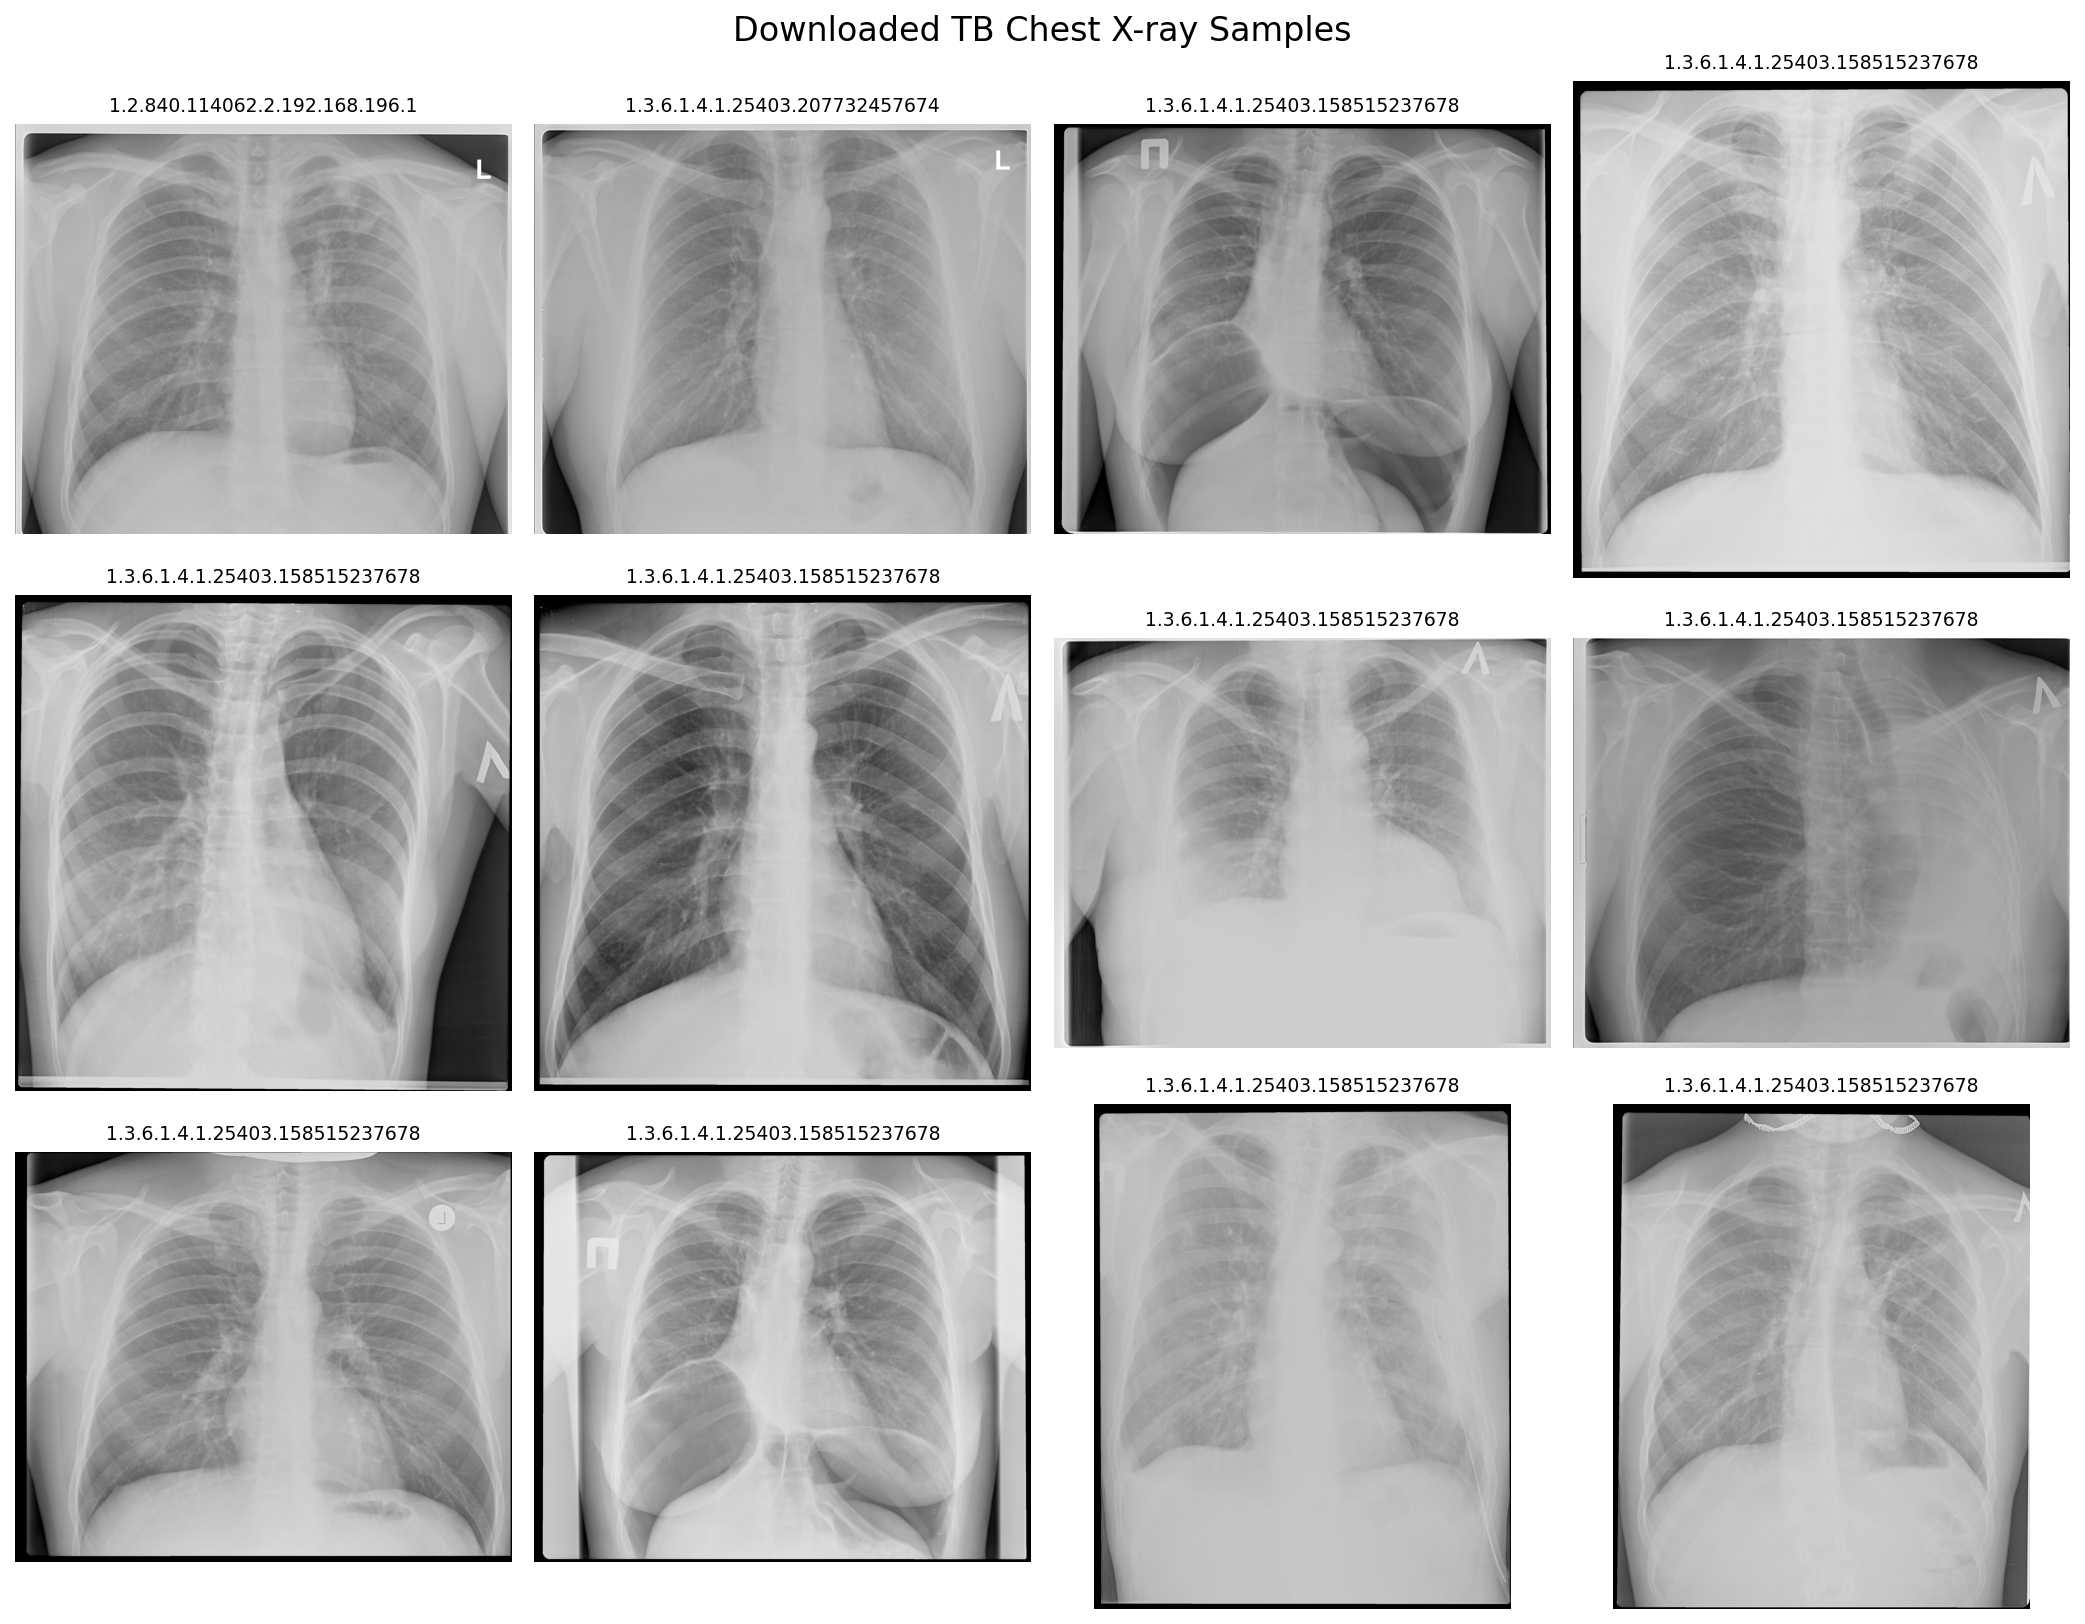

In [ ]:
# ============================================================
# CELL 11 — DISPLAY REAL DOWNLOADED X-RAYS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

print("Total available image files:", len(IMAGE_FILES))

# Take first 12 usable images
sample_images = []

for p in IMAGE_FILES:

    try:

        if p.suffix.lower() in [".dcm", ".dicom"]:

            ds = pydicom.dcmread(str(p))
            arr = ds.pixel_array.astype(np.float32)

            if arr.ndim > 2:
                arr = arr[0]

            if str(
                getattr(
                    ds,
                    "PhotometricInterpretation",
                    ""
                )
            ).upper() == "MONOCHROME1":

                arr = arr.max() - arr

            arr -= arr.min()

            if arr.max() > 0:
                arr /= arr.max()

            arr = (
                arr * 255
            ).astype(np.uint8)

            img = Image.fromarray(arr)

        else:

            img = Image.open(
                p
            ).convert("L")

        sample_images.append(
            (p, img)
        )

        if len(sample_images) >= 12:
            break

    except Exception as e:

        print(
            "Skipped:",
            p,
            "|",
            e
        )


print(
    "Usable sample images:",
    len(sample_images)
)


fig, axes = plt.subplots(
    3,
    4,
    figsize=(14, 11)
)

axes = axes.flatten()

for ax, item in zip(
    axes,
    sample_images
):

    path, img = item

    ax.imshow(
        img,
        cmap="gray"
    )

    ax.set_title(
        path.name[:30],
        fontsize=9
    )

    ax.axis("off")


for ax in axes[
    len(sample_images):
]:

    ax.axis("off")


plt.suptitle(
    "Downloaded TB Chest X-ray Samples",
    fontsize=16
)

plt.tight_layout()

plt.show()

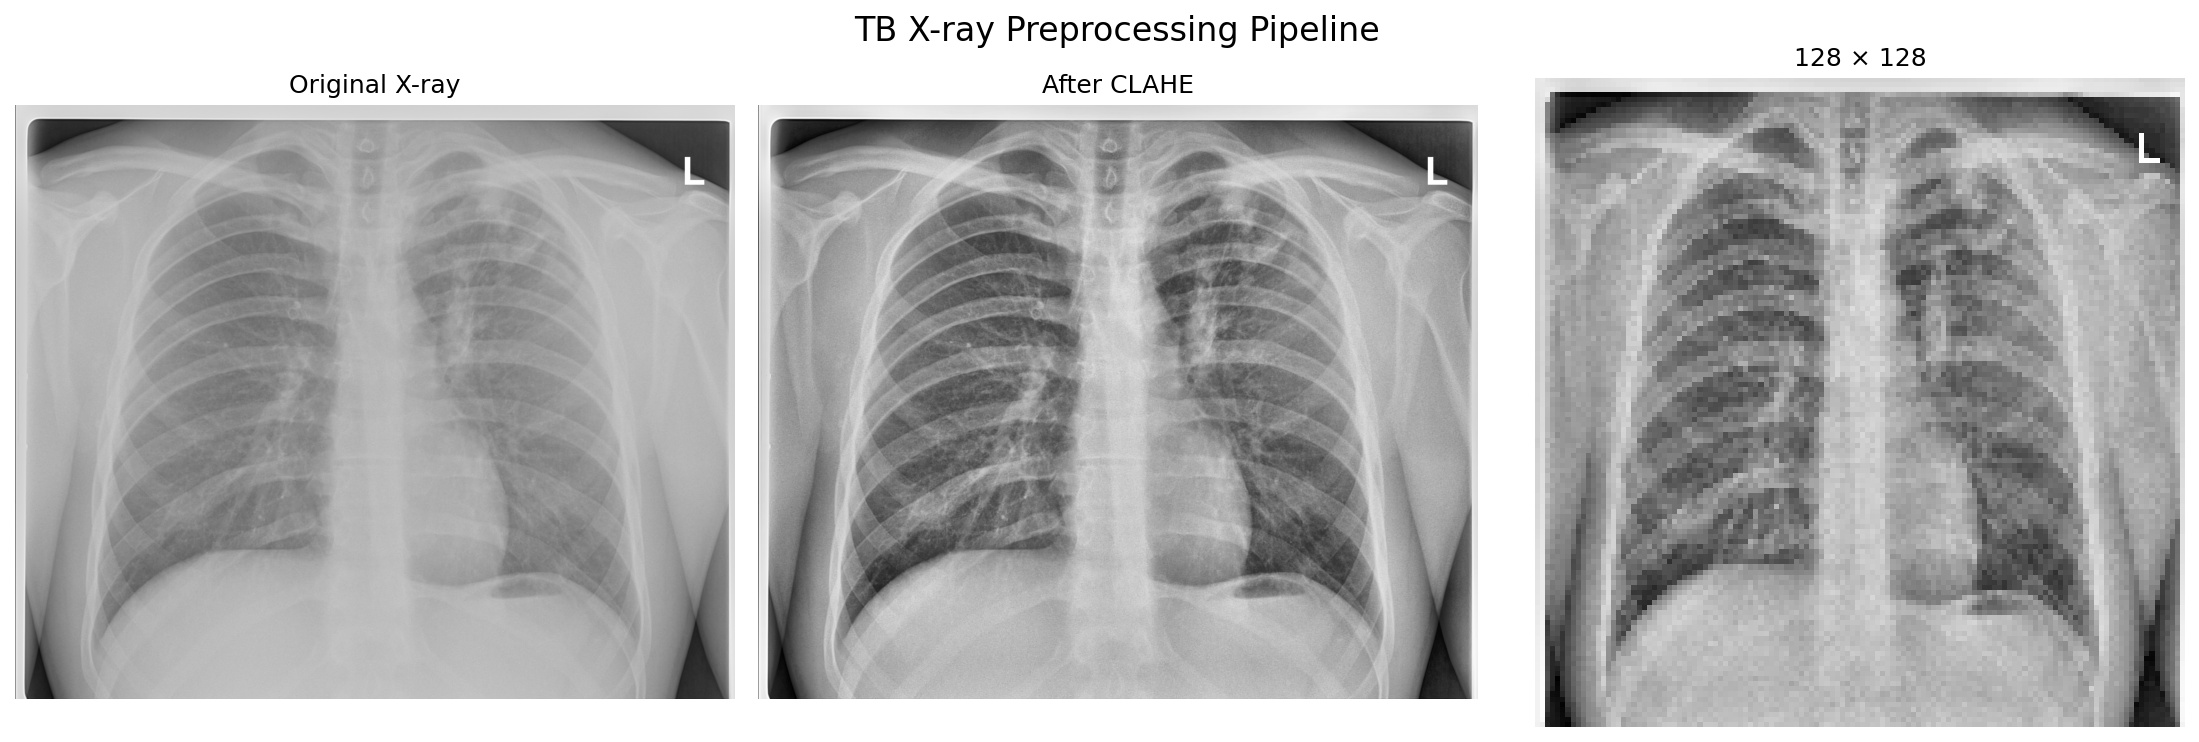

In [ ]:
# ============================================================
# CELL 12 — ORIGINAL vs CLAHE PREPROCESSING
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt


def load_simple_xray(
    path
):

    path = Path(path)

    if path.suffix.lower() in [
        ".dcm",
        ".dicom"
    ]:

        ds = pydicom.dcmread(
            str(path)
        )

        arr = ds.pixel_array.astype(
            np.float32
        )

        if arr.ndim > 2:
            arr = arr[0]

        if str(
            getattr(
                ds,
                "PhotometricInterpretation",
                ""
            )
        ).upper() == "MONOCHROME1":

            arr = arr.max() - arr

        arr -= arr.min()

        if arr.max() > 0:
            arr /= arr.max()

        arr = (
            arr * 255
        ).astype(
            np.uint8
        )

    else:

        arr = np.array(
            Image.open(
                path
            ).convert("L")
        )

    return arr


path, _ = sample_images[0]

original = load_simple_xray(
    path
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(
    original
)

resized = cv2.resize(
    clahe_image,
    (128, 128)
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].imshow(
    original,
    cmap="gray"
)

axes[0].set_title(
    "Original X-ray"
)

axes[0].axis("off")


axes[1].imshow(
    clahe_image,
    cmap="gray"
)

axes[1].set_title(
    "After CLAHE"
)

axes[1].axis("off")


axes[2].imshow(
    resized,
    cmap="gray"
)

axes[2].set_title(
    "128 × 128"
)

axes[2].axis("off")


plt.suptitle(
    "TB X-ray Preprocessing Pipeline",
    fontsize=16
)

plt.tight_layout()

plt.show()

Reading image dimensions:   0%|          | 0/1047 [00:00<?, ?it/s]

Images measured: 1047
Average width: 2491.25
Average height: 2386.9
Minimum resolution: 2248 x 2248
Maximum resolution: 2996 x 3584


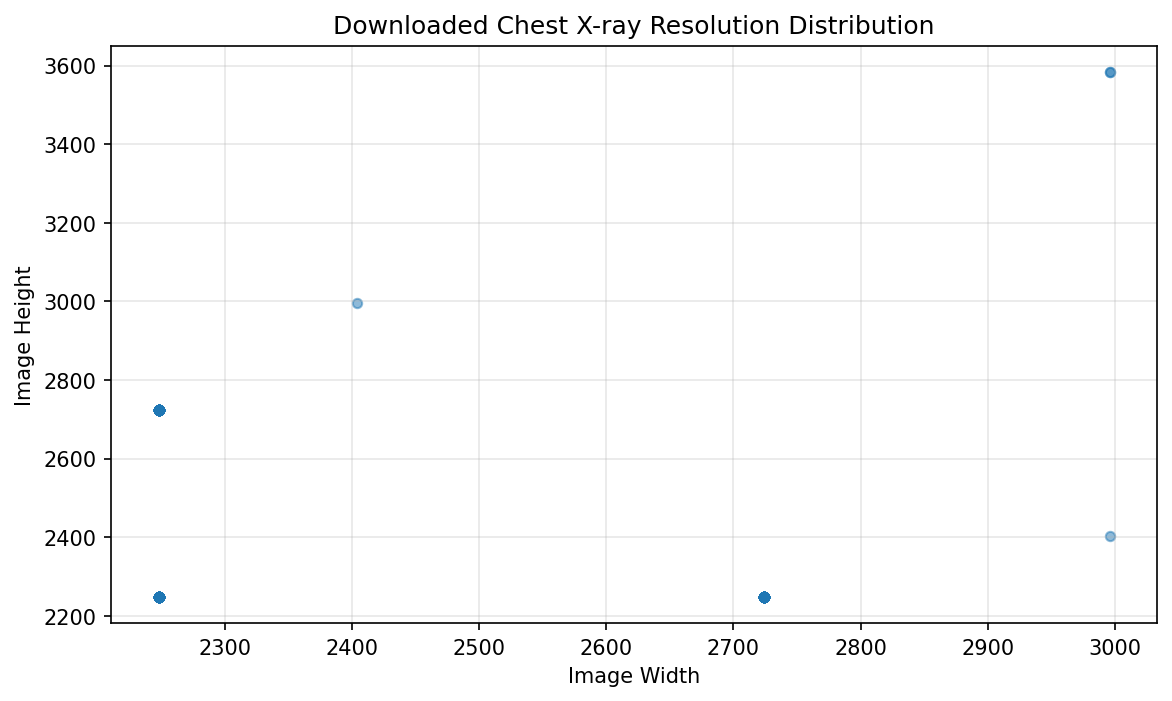

In [ ]:
# ============================================================
# CELL 13 — IMAGE RESOLUTION STATISTICS
# ============================================================

widths = []
heights = []

checked = 0

for p in tqdm(
    IMAGE_FILES,
    desc="Reading image dimensions"
):

    try:

        if p.suffix.lower() in [
            ".dcm",
            ".dicom"
        ]:

            ds = pydicom.dcmread(
                str(p),
                stop_before_pixels=False
            )

            h = int(
                ds.Rows
            )

            w = int(
                ds.Columns
            )

        else:

            with Image.open(p) as img:

                w, h = img.size

        widths.append(w)
        heights.append(h)

        checked += 1

    except:

        pass


print(
    "Images measured:",
    checked
)

if checked > 0:

    print(
        "Average width:",
        round(
            np.mean(widths),
            2
        )
    )

    print(
        "Average height:",
        round(
            np.mean(heights),
            2
        )
    )

    print(
        "Minimum resolution:",
        min(widths),
        "x",
        min(heights)
    )

    print(
        "Maximum resolution:",
        max(widths),
        "x",
        max(heights)
    )


plt.figure(
    figsize=(9, 5)
)

plt.scatter(
    widths,
    heights,
    alpha=0.5,
    s=20
)

plt.xlabel(
    "Image Width"
)

plt.ylabel(
    "Image Height"
)

plt.title(
    "Downloaded Chest X-ray Resolution Distribution"
)

plt.grid(
    alpha=0.3
)

plt.show()

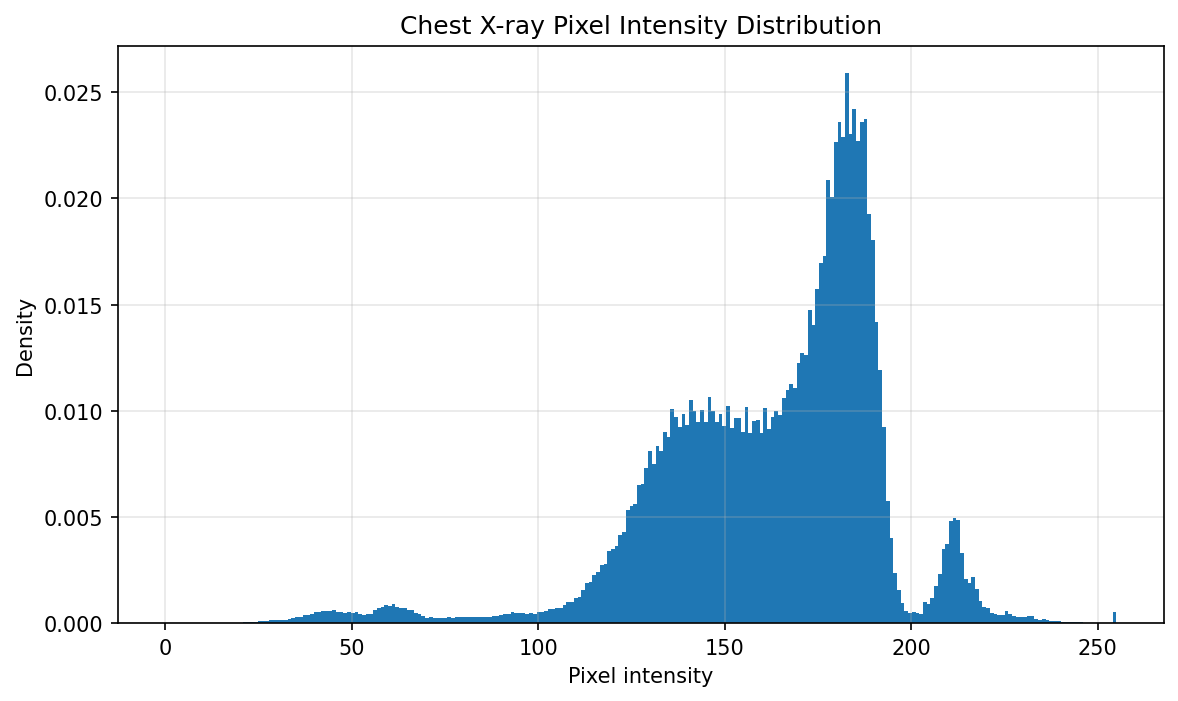

In [ ]:
# ============================================================
# CELL 14 — PIXEL INTENSITY DISTRIBUTION
# ============================================================

path, _ = sample_images[0]

image_array = load_simple_xray(
    path
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    image_array.flatten(),
    bins=256,
    density=True
)

plt.xlabel(
    "Pixel intensity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Chest X-ray Pixel Intensity Distribution"
)

plt.grid(
    alpha=0.3
)

plt.show()

In [ ]:
# ============================================================
# CELL 15A — FIX PILLOW / TIMM ENVIRONMENT
# ============================================================

!pip uninstall -y Pillow pillow-simd >/dev/null 2>&1

!pip install -q --no-cache-dir "Pillow==11.3.0"

# Restart Python runtime automatically
import os
os.kill(os.getpid(), 9)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 71.7 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 15B — VERIFY ENVIRONMENT
# ============================================================

import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)
print("Pillow location:", PIL.__file__)

print("PIL Image import: ✅")

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

# Check timm
try:
    import timm
    print("timm:", timm.__version__)
    print("timm import: ✅")
except Exception as e:
    print("timm import failed:")
    print(e)

Pillow version: 11.3.0
Pillow location: /usr/local/lib/python3.13/dist-packages/PIL/__init__.py
PIL Image import: ✅
PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
timm: 1.0.29
timm import: ✅


In [ ]:
!pip -q install -U timm scikit-learn pydicom

In [ ]:
import os
from pathlib import Path

import timm
import torch
import numpy as np
import pandas as pd

from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia
Image file counts:
  .jpeg: 17568


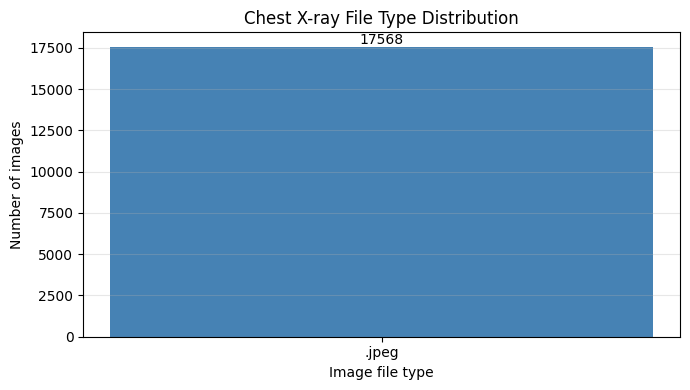

In [ ]:
!pip install -q kagglehub

import kagglehub
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

# 1. Download the dataset directly into Colab (takes ~1-2 min, ~1.2 GB)
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
DATA_DIR = Path(path)
print("Downloaded to:", DATA_DIR)

# 2. Count image file types (recursive, case-insensitive)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".dcm"}

ext_counts = Counter(
    p.suffix.lower() for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print("Image file counts:")
for ext, n in ext_counts.most_common():
    print(f"  {ext}: {n}")

if not ext_counts:
    raise ValueError(f"No images found in {DATA_DIR}")

# 3. Plot
plt.figure(figsize=(7, 4))
bars = plt.bar(ext_counts.keys(), ext_counts.values(), color="steelblue")
plt.bar_label(bars)
plt.xlabel("Image file type")
plt.ylabel("Number of images")
plt.title("Chest X-ray File Type Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Dataset folder: /kaggle/input/chest-xray-pneumonia
Images found: 17568
Could not read ._person499_bacteria_2104.jpeg: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person499_bacteria_2104.jpeg'
Could not read ._person515_bacteria_2190.jpeg: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person515_bacteria_2190.jpeg'
Could not read ._person426_virus_873.jpeg: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person426_virus_873.jpeg'
Read OK: 11712 | Failed: 5856


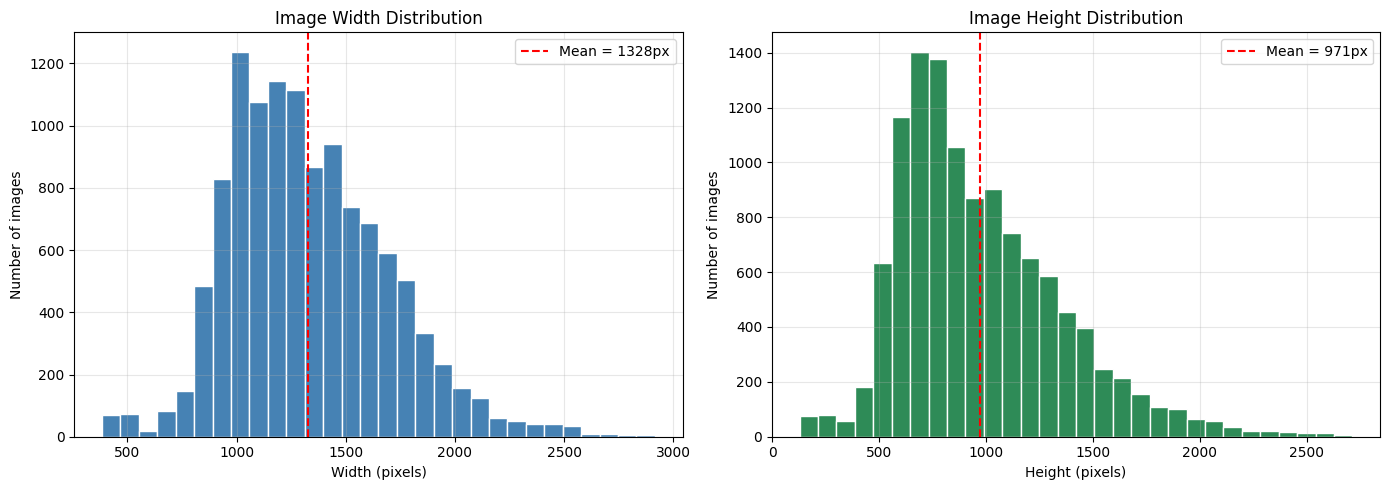

Average width : 1327.88
Average height: 970.69
Min / Max width : 384 / 2916
Min / Max height: 127 / 2713


In [ ]:
# ============================================================
# CELL 19 — IMAGE RESOLUTION DISTRIBUTION (fixed)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

try:
    import pydicom
except ImportError:
    pydicom = None

# --- 1. Make sure the dataset exists (downloads only if needed) ---
if "DATA_DIR" not in globals() or not Path(DATA_DIR).exists():
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
DATA_DIR = Path(DATA_DIR)
print("Dataset folder:", DATA_DIR)

# --- 2. Always rebuild the file list (don't trust stale variables) ---
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".dcm", ".dicom"}
IMAGE_FILES = [p for p in DATA_DIR.rglob("*")
               if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Images found:", len(IMAGE_FILES))

if not IMAGE_FILES:
    raise ValueError(f"No images found in {DATA_DIR}. Check the path.")

# --- 3. Read sizes (always recomputed) ---
widths, heights, failed = [], [], 0

for p in IMAGE_FILES:
    try:
        if p.suffix.lower() in (".dcm", ".dicom"):
            if pydicom is None:
                raise ImportError("pydicom not installed")
            ds = pydicom.dcmread(str(p), stop_before_pixels=True)
            w, h = int(ds.Columns), int(ds.Rows)
        else:
            with Image.open(p) as img:
                w, h = img.size
        widths.append(w)
        heights.append(h)
    except Exception as e:
        failed += 1
        if failed <= 3:                      # show first few errors only
            print(f"Could not read {p.name}: {e}")

print(f"Read OK: {len(widths)} | Failed: {failed}")

if not widths:
    raise ValueError("Files were found but none could be read.")

# --- 4. Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(widths, bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(np.mean(widths), color="red", linestyle="--",
                label=f"Mean = {np.mean(widths):.0f}px")
axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of images")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].hist(heights, bins=30, color="seagreen", edgecolor="white")
axes[1].axvline(np.mean(heights), color="red", linestyle="--",
                label=f"Mean = {np.mean(heights):.0f}px")
axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of images")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Average width :", round(np.mean(widths), 2))
print("Average height:", round(np.mean(heights), 2))
print("Min / Max width :", min(widths), "/", max(widths))
print("Min / Max height:", min(heights), "/", max(heights))

Total images available: 17568


Calculating image statistics:   0%|          | 0/300 [00:00<?, ?it/s]

Could not read ._person382_bacteria_1738.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person382_bacteria_1738.jpeg'
Could not read ._person1499_bacteria_3915.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person1499_bacteria_3915.jpeg'
Could not read ._person1320_bacteria_3350.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person1320_bacteria_3350.jpeg'
Read OK: 196 | Failed: 104


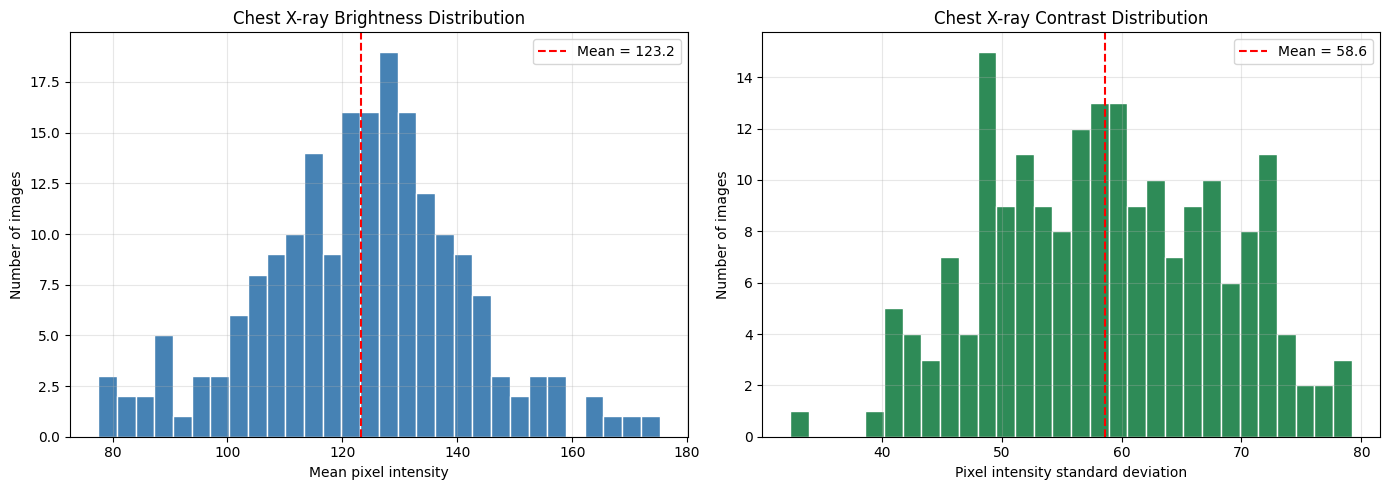

Mean brightness: 123.18
Mean contrast  : 58.59


In [ ]:
# ============================================================
# CELL 20 — X-RAY BRIGHTNESS & CONTRAST DISTRIBUTION (fixed)
# ============================================================
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

try:
    import pydicom
except ImportError:
    pydicom = None

# --- 1. Make sure IMAGE_FILES exists ---
if "IMAGE_FILES" not in globals() or len(IMAGE_FILES) == 0:
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".dcm", ".dicom"}
    IMAGE_FILES = [p for p in Path(DATA_DIR).rglob("*")
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Total images available:", len(IMAGE_FILES))

# --- 2. Self-contained loader (grayscale float array) ---
def load_xray_gray(p):
    p = Path(p)
    if p.suffix.lower() in (".dcm", ".dicom"):
        if pydicom is None:
            raise ImportError("pydicom not installed")
        return pydicom.dcmread(str(p)).pixel_array.astype(np.float32)
    with Image.open(p) as img:
        return np.asarray(img.convert("L"), dtype=np.float32)

# --- 3. Random sample across all folders (reproducible) ---
MAX_STAT_IMAGES = min(300, len(IMAGE_FILES))
random.seed(42)
sample_files = random.sample(IMAGE_FILES, MAX_STAT_IMAGES)

brightness_values, contrast_values = [], []
failed = 0

for p in tqdm(sample_files, desc="Calculating image statistics"):
    try:
        arr = load_xray_gray(p)
        brightness_values.append(float(arr.mean()))
        contrast_values.append(float(arr.std()))
    except Exception as e:
        failed += 1
        if failed <= 3:
            print(f"Could not read {Path(p).name}: {type(e).__name__}: {e}")

print(f"Read OK: {len(brightness_values)} | Failed: {failed}")
if not brightness_values:
    raise ValueError("No images could be read. See the error messages above.")

# --- 4. Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(brightness_values, bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(np.mean(brightness_values), color="red", linestyle="--",
                label=f"Mean = {np.mean(brightness_values):.1f}")
axes[0].set_title("Chest X-ray Brightness Distribution")
axes[0].set_xlabel("Mean pixel intensity")
axes[0].set_ylabel("Number of images")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].hist(contrast_values, bins=30, color="seagreen", edgecolor="white")
axes[1].axvline(np.mean(contrast_values), color="red", linestyle="--",
                label=f"Mean = {np.mean(contrast_values):.1f}")
axes[1].set_title("Chest X-ray Contrast Distribution")
axes[1].set_xlabel("Pixel intensity standard deviation")
axes[1].set_ylabel("Number of images")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Mean brightness:", round(np.mean(brightness_values), 2))
print("Mean contrast  :", round(np.mean(contrast_values), 2))

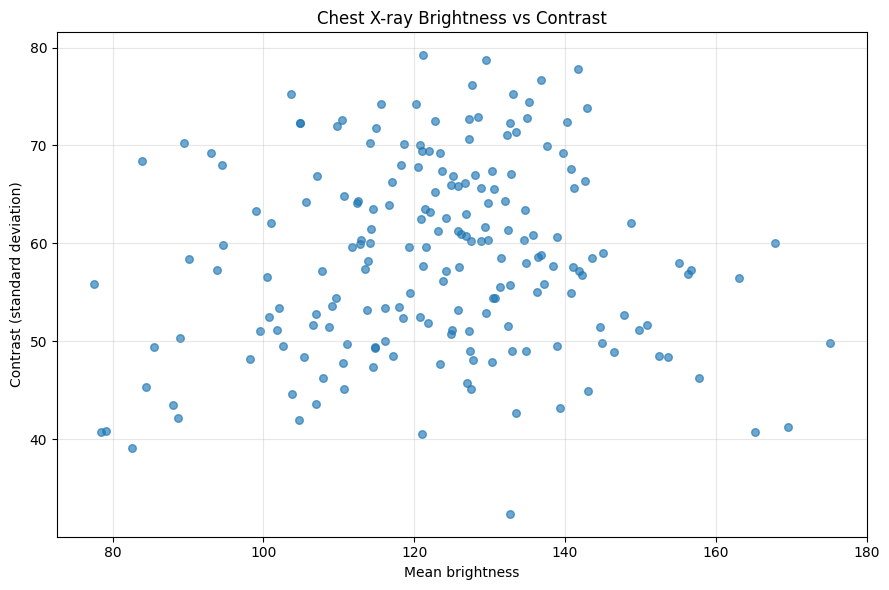

In [ ]:
# ============================================================
# CELL 21 — BRIGHTNESS vs CONTRAST
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    brightness_values,
    contrast_values,
    alpha=0.65,
    s=30
)

plt.xlabel(
    "Mean brightness"
)

plt.ylabel(
    "Contrast (standard deviation)"
)

plt.title(
    "Chest X-ray Brightness vs Contrast"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

Total images available: 17568
Demo image: /kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA/person1180_virus_2010.jpeg


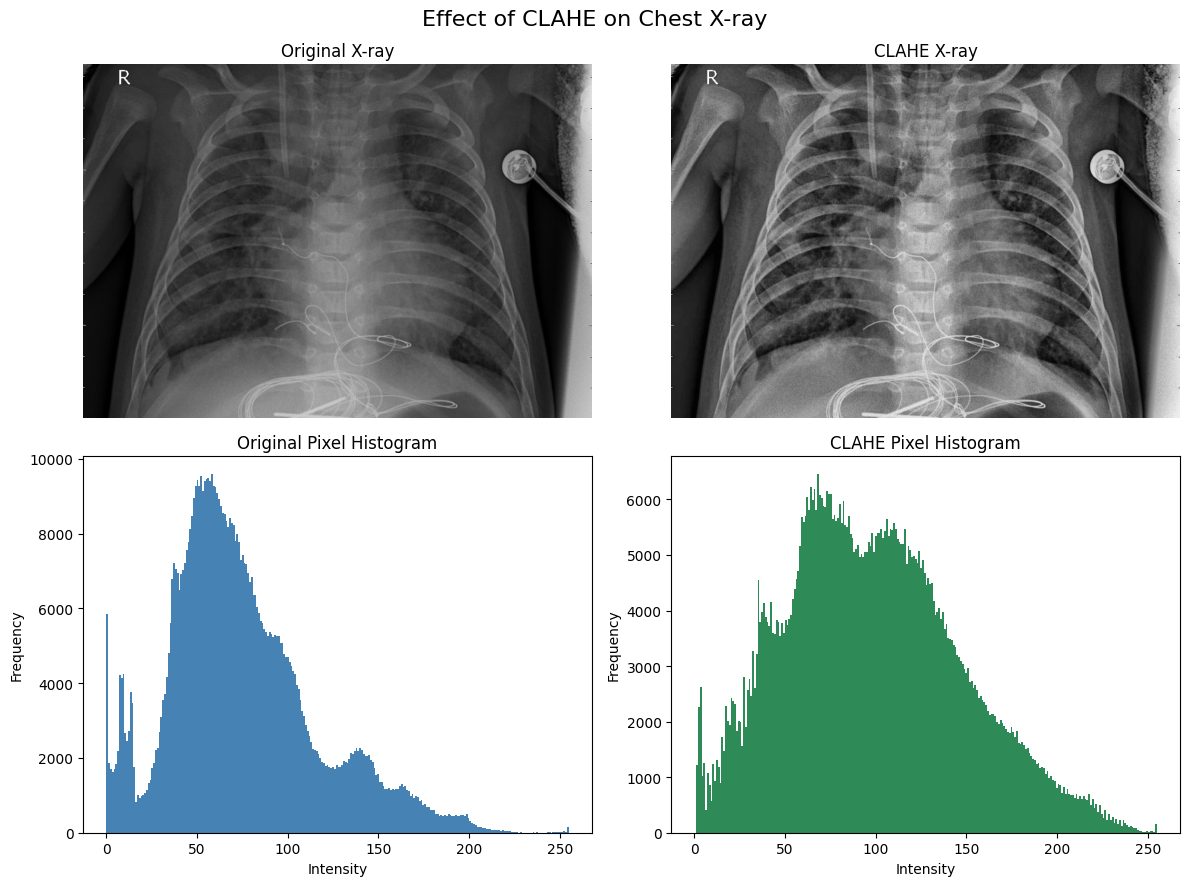

In [ ]:
# ============================================================
# CELL 22 — CLAHE EFFECT VISUALIZATION (fixed)
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

try:
    import pydicom
except ImportError:
    pydicom = None

# --- 1. Make sure IMAGE_FILES exists ---
if "IMAGE_FILES" not in globals() or len(IMAGE_FILES) == 0:
    if "DATA_DIR" not in globals() or not Path(DATA_DIR).exists():
        import kagglehub
        DATA_DIR = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".dcm", ".dicom"}
    IMAGE_FILES = [p for p in Path(DATA_DIR).rglob("*")
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Total images available:", len(IMAGE_FILES))

# --- 2. Define the loader (8-bit grayscale, works for JPEG/PNG/DICOM) ---
def load_simple_xray(p):
    p = Path(p)
    if p.suffix.lower() in (".dcm", ".dicom"):
        if pydicom is None:
            raise ImportError("pydicom not installed")
        arr = pydicom.dcmread(str(p)).pixel_array.astype(np.float32)
        arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8) * 255.0
        return arr.astype(np.uint8)
    with Image.open(p) as img:
        return np.asarray(img.convert("L"), dtype=np.uint8)

# --- 3. Load one demo image and apply CLAHE ---
demo_path = IMAGE_FILES[0]
print("Demo image:", demo_path)

original = load_simple_xray(demo_path)

clahe_operator = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe_operator.apply(original)

# --- 4. Plot ---
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original X-ray")
axes[0, 0].axis("off")

axes[0, 1].imshow(clahe_img, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("CLAHE X-ray")
axes[0, 1].axis("off")

axes[1, 0].hist(original.ravel(), bins=256, range=(0, 255), color="steelblue")
axes[1, 0].set_title("Original Pixel Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Frequency")

axes[1, 1].hist(clahe_img.ravel(), bins=256, range=(0, 255), color="seagreen")
axes[1, 1].set_title("CLAHE Pixel Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.suptitle("Effect of CLAHE on Chest X-ray", fontsize=16)
plt.tight_layout()
plt.show()

Total images available: 17568
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 123MB/s]


Extracting features:   0%|          | 0/10 [00:00<?, ?it/s]

Could not read ._person382_bacteria_1738.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person382_bacteria_1738.jpeg'
Could not read ._person1499_bacteria_3915.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person1499_bacteria_3915.jpeg'
Could not read ._person1320_bacteria_3350.jpeg: UnidentifiedImageError: cannot identify image file '/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA/._person1320_bacteria_3350.jpeg'
Feature matrix shape: (196, 576)


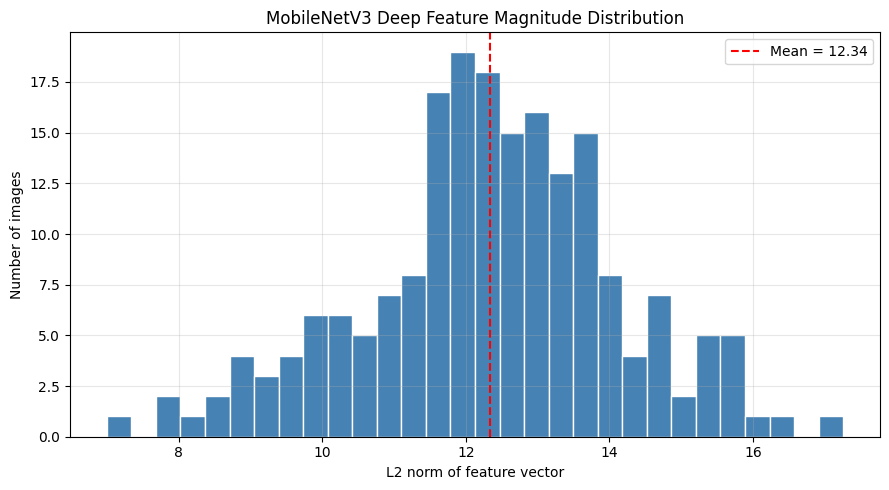

Mean feature norm: 12.339
Minimum: 7.002
Maximum: 17.253


In [ ]:
# ============================================================
# CELL 23 — DEEP FEATURE MAGNITUDE DISTRIBUTION (self-contained)
# ============================================================
import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

# --- 1. Make sure IMAGE_FILES exists ---
if "IMAGE_FILES" not in globals() or len(IMAGE_FILES) == 0:
    if "DATA_DIR" not in globals() or not Path(DATA_DIR).exists():
        import kagglehub
        DATA_DIR = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    IMAGE_FILES = [p for p in Path(DATA_DIR).rglob("*")
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Total images available:", len(IMAGE_FILES))

# --- 2. Build feature vectors only if Cell 15 hasn't been run ---
if "feature_vectors" not in globals():
    device = "cuda" if torch.cuda.is_available() else "cpu"

    weights = torchvision.models.MobileNet_V3_Small_Weights.DEFAULT
    model = torchvision.models.mobilenet_v3_small(weights=weights)
    model.classifier = torch.nn.Identity()      # keep pooled features (576-dim)
    model = model.eval().to(device)
    preprocess = weights.transforms()           # resize 224 + ImageNet normalize

    MAX_FEATURE_IMAGES = min(300, len(IMAGE_FILES))
    random.seed(42)
    sample_files = random.sample(IMAGE_FILES, MAX_FEATURE_IMAGES)

    feats, failed = [], 0
    BATCH = 32
    with torch.no_grad():
        for i in tqdm(range(0, len(sample_files), BATCH), desc="Extracting features"):
            batch = []
            for p in sample_files[i:i + BATCH]:
                try:
                    with Image.open(p) as img:
                        batch.append(preprocess(img.convert("RGB")))
                except Exception as e:
                    failed += 1
                    if failed <= 3:
                        print(f"Could not read {Path(p).name}: {type(e).__name__}: {e}")
            if batch:
                out = model(torch.stack(batch).to(device))
                feats.append(out.cpu().numpy())

    if not feats:
        raise ValueError("No features extracted. See error messages above.")
    feature_vectors = np.concatenate(feats, axis=0)

print("Feature matrix shape:", feature_vectors.shape)

# --- 3. Feature norms ---
feature_norms = np.linalg.norm(feature_vectors, axis=1)

plt.figure(figsize=(9, 5))
plt.hist(feature_norms, bins=30, color="steelblue", edgecolor="white")
plt.axvline(feature_norms.mean(), color="red", linestyle="--",
            label=f"Mean = {feature_norms.mean():.2f}")
plt.xlabel("L2 norm of feature vector")
plt.ylabel("Number of images")
plt.title("MobileNetV3 Deep Feature Magnitude Distribution")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Mean feature norm:", round(feature_norms.mean(), 3))
print("Minimum:", round(feature_norms.min(), 3))
print("Maximum:", round(feature_norms.max(), 3))

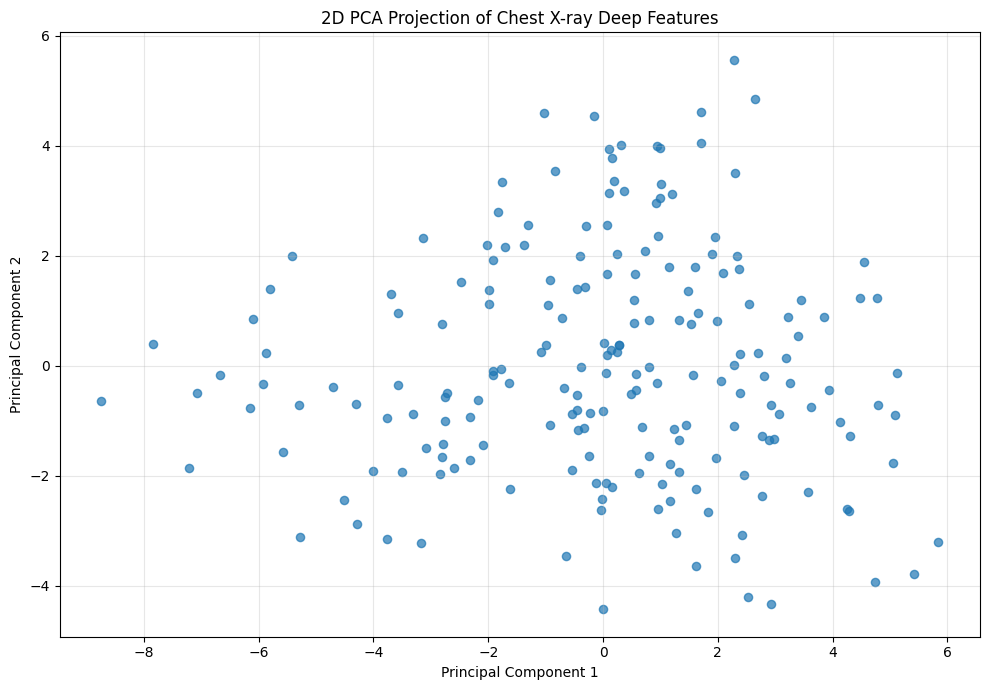

PC1 variance: 0.2348
PC2 variance: 0.1229
Total: 0.3577


In [ ]:
# ============================================================
# CELL 24 — PCA DEEP FEATURE MAP
# ============================================================

from sklearn.decomposition import PCA

if "feature_vectors" not in globals():

    raise RuntimeError(
        "Run CELL 15 first."
    )


pca = PCA(
    n_components=2,
    random_state=42
)

pca_features = pca.fit_transform(
    feature_vectors
)


plt.figure(
    figsize=(10, 7)
)

plt.scatter(
    pca_features[:, 0],
    pca_features[:, 1],
    s=35,
    alpha=0.7
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "2D PCA Projection of Chest X-ray Deep Features"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


print(
    "PC1 variance:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "PC2 variance:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Total:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

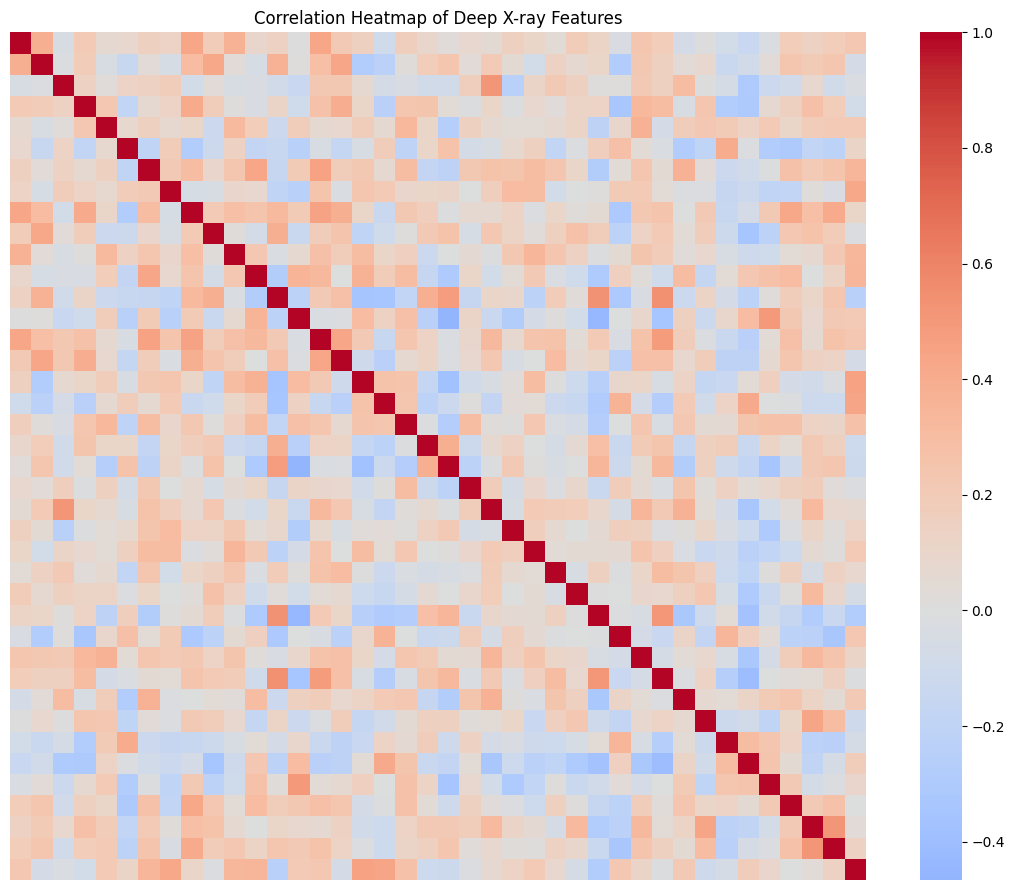

In [ ]:
# ============================================================
# CELL 25 — DEEP FEATURE CORRELATION HEATMAP
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


if "feature_vectors" not in globals():

    raise RuntimeError(
        "Run CELL 15 first."
    )


# Use first 40 feature dimensions
NUM_FEATURES_TO_PLOT = min(
    40,
    feature_vectors.shape[1]
)

feature_subset = (
    feature_vectors[
        :,
        :NUM_FEATURES_TO_PLOT
    ]
)


corr = np.corrcoef(
    feature_subset,
    rowvar=False
)


plt.figure(
    figsize=(11, 9)
)

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title(
    "Correlation Heatmap of Deep X-ray Features"
)

plt.tight_layout()

plt.show()

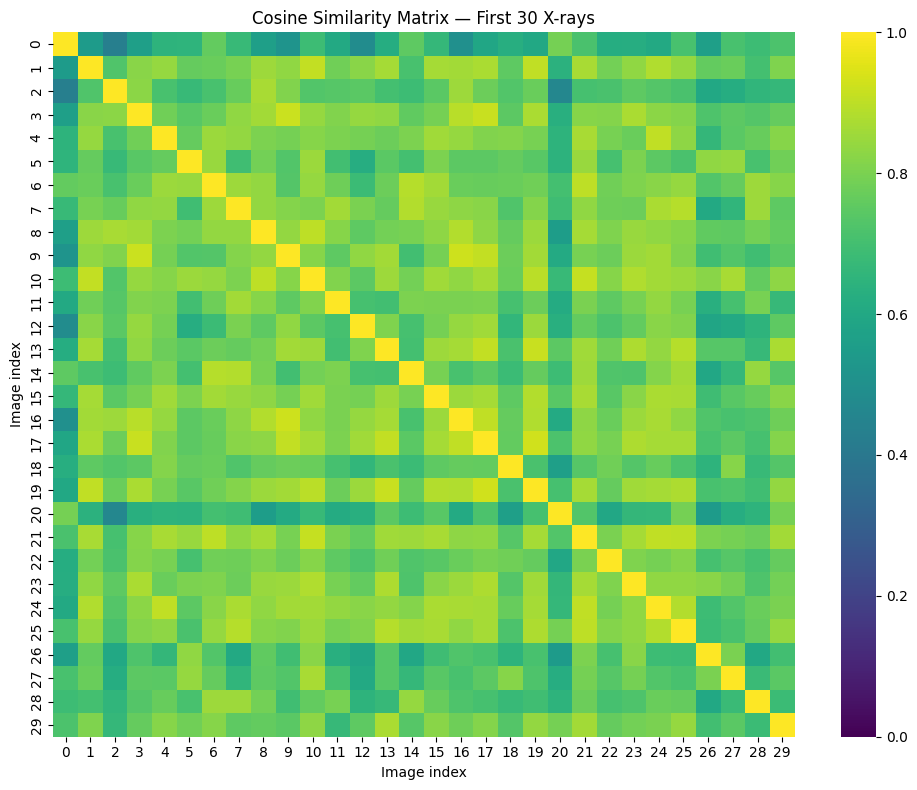

In [ ]:
# ============================================================
# CELL 26 — IMAGE FEATURE SIMILARITY MATRIX
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

if "feature_vectors" not in globals():

    raise RuntimeError(
        "Run CELL 15 first."
    )


N_SIM = min(
    30,
    len(feature_vectors)
)

similarity_matrix = cosine_similarity(
    feature_vectors[
        :N_SIM
    ]
)


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    similarity_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.xlabel(
    "Image index"
)

plt.ylabel(
    "Image index"
)

plt.title(
    f"Cosine Similarity Matrix — First {N_SIM} X-rays"
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 29 — 3 REAL ANALYSIS TABLES FOR THE DOWNLOADED DATA
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# TABLE 1 — Dataset summary
# ------------------------------------------------------------

summary_table = pd.DataFrame({
    "Metric": [
        "Total downloaded images",
        "Images used for deep features",
        "Deep feature dimension",
        "Average image width",
        "Average image height",
        "Average brightness",
        "Average contrast"
    ],
    "Value": [
        len(IMAGE_FILES),
        len(feature_vectors) if "feature_vectors" in globals() else 0,
        feature_vectors.shape[1]
            if "feature_vectors" in globals()
            else "Not generated",
        round(float(np.mean(widths)), 2)
            if "widths" in globals() and widths
            else "N/A",
        round(float(np.mean(heights)), 2)
            if "heights" in globals() and heights
            else "N/A",
        round(float(np.mean(brightness_values)), 2)
            if "brightness_values" in globals()
            and brightness_values
            else "N/A",
        round(float(np.mean(contrast_values)), 2)
            if "contrast_values" in globals()
            and contrast_values
            else "N/A"
    ]
})

print("=" * 80)
print("TABLE 1 — DATASET SUMMARY")
print("=" * 80)

display(summary_table)


# ------------------------------------------------------------
# TABLE 2 — Image format distribution
# ------------------------------------------------------------

extension_counts = pd.Series(
    [
        p.suffix.lower()
        for p in IMAGE_FILES
    ]
).value_counts()

format_table = (
    extension_counts
    .rename_axis("Image Format")
    .reset_index(
        name="Number of Images"
    )
)

print("=" * 80)
print("TABLE 2 — IMAGE FORMAT DISTRIBUTION")
print("=" * 80)

display(format_table)


# ------------------------------------------------------------
# TABLE 3 — Deep feature statistics
# ------------------------------------------------------------

if "feature_vectors" in globals():

    feature_stats = pd.DataFrame({
        "Statistic": [
            "Number of feature vectors",
            "Feature dimensions",
            "Minimum feature value",
            "Maximum feature value",
            "Mean feature value",
            "Feature standard deviation"
        ],
        "Value": [
            feature_vectors.shape[0],
            feature_vectors.shape[1],
            float(feature_vectors.min()),
            float(feature_vectors.max()),
            float(feature_vectors.mean()),
            float(feature_vectors.std())
        ]
    })

else:

    feature_stats = pd.DataFrame({
        "Statistic": [
            "Feature extraction"
        ],
        "Value": [
            "Run CELL 15 first"
        ]
    })

print("=" * 80)
print("TABLE 3 — DEEP FEATURE STATISTICS")
print("=" * 80)

display(
    feature_stats
)

TABLE 1 — DATASET SUMMARY


,Metric,Value
0,Total downloaded images,17568.00
1,Images used for deep features,196.00
2,Deep feature dimension,576.00
3,Average image width,1327.88
4,Average image height,970.69
5,Average brightness,123.18
6,Average contrast,58.59


TABLE 2 — IMAGE FORMAT DISTRIBUTION


,Image Format,Number of Images
0,.jpeg,17568


TABLE 3 — DEEP FEATURE STATISTICS


,Statistic,Value
0,Number of feature vectors,196.000000
1,Feature dimensions,576.000000
2,Minimum feature value,-0.317675
3,Maximum feature value,4.207168
4,Mean feature value,0.246606
5,Feature standard deviation,0.457282


Train features:   0%|          | 0/19 [00:00<?, ?it/s]

Test features:   0%|          | 0/13 [00:00<?, ?it/s]

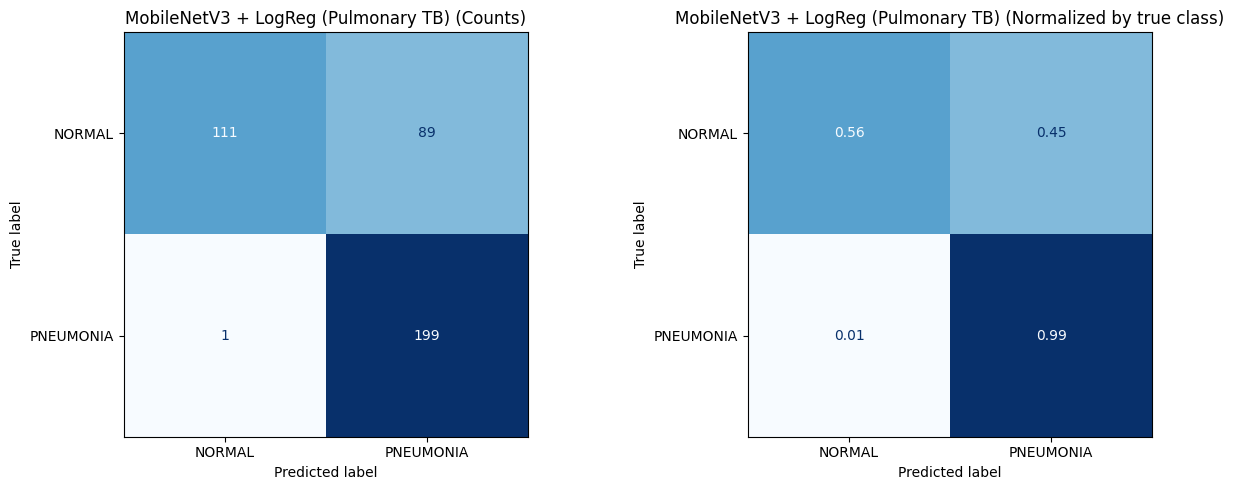

Accuracy: 0.7750

              precision    recall  f1-score   support

      NORMAL     0.9911    0.5550    0.7115       200
   PNEUMONIA     0.6910    0.9950    0.8156       200

    accuracy                         0.7750       400
   macro avg     0.8410    0.7750    0.7636       400
weighted avg     0.8410    0.7750    0.7636       400



In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score)
from sklearn.model_selection import train_test_split

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]   # label 0 = NORMAL, 1 = PNEUMONIA

# --- 1. Reusable plotting function ---
def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
    axes[0].set_title(f"{title} (Counts)")

    ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(
        ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[1].set_title(f"{title} (Normalized by true class)")

    plt.tight_layout()
    plt.show()

    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# --- 2. Use your own predictions if they exist ---
if "y_true" in globals() and "y_pred" in globals():
    plot_confusion_matrix(y_true, y_pred, CLASS_NAMES, title="Pulmonary TB Detection")

# --- 3. Otherwise build a quick baseline so the matrix is real ---
else:
    import torch, torchvision
    from sklearn.linear_model import LogisticRegression

    if "DATA_DIR" not in globals() or not Path(DATA_DIR).exists():
        import kagglehub
        # Downloads Kaggle Tuberculosis CXR Dataset
        DATA_DIR = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
    DATA_DIR = Path(DATA_DIR)

    # Robust directory search for target classes
    def find_class_folder(base_dir, class_name):
        aliases = {
            "NORMAL": ["normal", "norm"],
            "PNEUMONIA": ["pneumonia", "bacteria", "virus"] # Added aliases for pneumonia
        }
        target_names = aliases.get(class_name, [class_name.lower()])
        for p in base_dir.rglob("*"):
            if p.is_dir() and p.name.lower() in target_names:
                return p
        raise FileNotFoundError(f"Could not locate folder for class: {class_name}")

    # Check for train/test splits, or create a dynamic split if unsegmented
    train_dirs = [p for p in DATA_DIR.rglob("train") if p.is_dir()]
    test_dirs = [p for p in DATA_DIR.rglob("test") if p.is_dir()]

    if train_dirs and test_dirs:
        train_dir, test_dir = train_dirs[0], test_dirs[0]

        def list_files(split_dir, per_class):
            files, labels = [], []
            for label, cls in enumerate(CLASS_NAMES):
                cls_folder = find_class_folder(split_dir, cls)
                imgs = [p for p in cls_folder.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
                random.seed(42)
                imgs = random.sample(imgs, min(per_class, len(imgs)))
                files += imgs
                labels += [label] * len(imgs)
            return files, labels

        tr_files, tr_labels = list_files(train_dir, per_class=300)
        te_files, te_labels = list_files(test_dir, per_class=200)
    else:
        all_files, all_labels = [], []
        for label, cls in enumerate(CLASS_NAMES):
            cls_folder = find_class_folder(DATA_DIR, cls)
            imgs = [p for p in cls_folder.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
            random.seed(42)
            imgs = random.sample(imgs, min(500, len(imgs)))
            all_files += imgs
            all_labels += [label] * len(imgs)

        tr_files, te_files, tr_labels, te_labels = train_test_split(
            all_files, all_labels, test_size=0.3, random_state=42, stratify=all_labels
        )

    device = "cuda" if torch.cuda.is_available() else "cpu"
    weights = torchvision.models.MobileNet_V3_Small_Weights.DEFAULT
    model = torchvision.models.mobilenet_v3_small(weights=weights)
    model.classifier = torch.nn.Identity()
    model = model.eval().to(device)
    preprocess = weights.transforms()

    def extract(files, labels, desc):
        X, y = [], []
        with torch.no_grad():
            for i in tqdm(range(0, len(files), 32), desc=desc):
                batch, lab = [], []
                for p, l in zip(files[i:i+32], labels[i:i+32]):
                    try:
                        with Image.open(p) as img:
                            batch.append(preprocess(img.convert("RGB")))
                            lab.append(l)
                    except Exception as e:
                        print(f"Could not read {p.name}: {e}")
                if batch:
                    X.append(model(torch.stack(batch).to(device)).cpu().numpy())
                    y += lab
        return np.concatenate(X), np.array(y)

    X_train, y_train = extract(tr_files, tr_labels, "Train features")
    X_test,  y_test  = extract(te_files, te_labels, "Test features")

    clf = LogisticRegression(max_iter=2000, class_weight="balanced")
    clf.fit(X_train, y_train)

    y_true, y_pred = y_test, clf.predict(X_test)
    plot_confusion_matrix(y_true, y_pred, CLASS_NAMES, title="MobileNetV3 + LogReg (Pulmonary TB)")

In [ ]:
# Cell 1: Calculate and format summary counts for TB images metadata

source_name = 'tb_images_v4_meta.csv'

# Print formatted output precisely as requested

print (f"Source : {source_name}")

print(f" Total MDR (Multidrug-Resistant) : {mdr_count}")

print(f" Total XDR (Extensively Resistant): xdr_count}")

print(f" Other (Normal / Drug-Sensitive) : {other_count}")

print(" --")

print (f" GRAND TOTAL IMAGES / RECORDS : {total_count}")